Epoch 1/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 515us/step - accuracy: 0.8150 - loss: 0.6989 - val_accuracy: 0.9032 - val_loss: 0.3455
Epoch 2/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 472us/step - accuracy: 0.9069 - loss: 0.3264 - val_accuracy: 0.9202 - val_loss: 0.2777
Epoch 3/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 473us/step - accuracy: 0.9217 - loss: 0.2714 - val_accuracy: 0.9319 - val_loss: 0.2408
Epoch 4/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 469us/step - accuracy: 0.9318 - loss: 0.2356 - val_accuracy: 0.9408 - val_loss: 0.2151
Epoch 5/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 473us/step - accuracy: 0.9395 - loss: 0.2088 - val_accuracy: 0.9460 - val_loss: 0.1956
Epoch 6/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 502us/step - accuracy: 0.9461 - loss: 0.1876 - val_accuracy: 0.9500 - val_loss: 0.1800
Epoch 7/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 467us/step - accuracy: 0.9515 - loss: 0.1701 - val_accuracy: 0.9532 - val_loss: 0.1678
Epoch 8/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 464us/step - accuracy: 0.9552 -

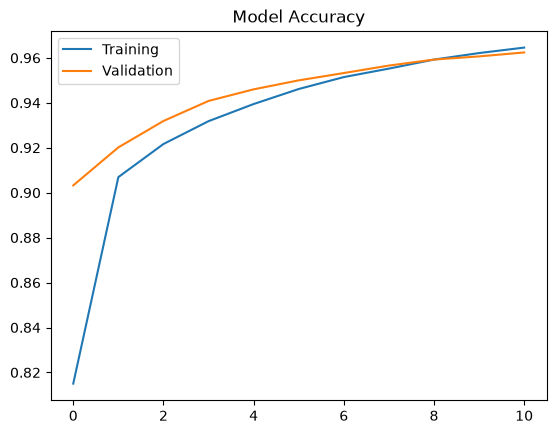

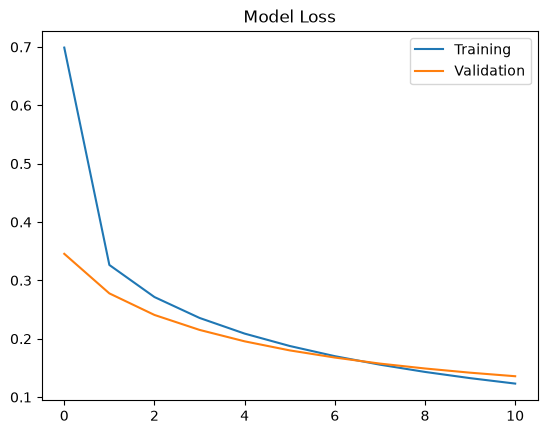

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Load dataset
train = pd.read_csv('FNN and CNN/HandWritten MNIST/mnist_train.csv')
test = pd.read_csv('FNN and CNN/HandWritten MNIST/mnist_test.csv')

X_train = train.drop('label', axis=1).values
y_train = train['label'].values

X_test = test.drop('label', axis=1).values
y_test = test['label'].values

# 2. Preprocess data
X_train = X_train / 255.0
X_test = X_test / 255.0

num_classes = 10

# 3. Build FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

# 4. Compile model
model.compile(
    optimizer=tf.keras.optimizers.SGD(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Train model
history = model.fit(
    X_train, y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.2
)

# 6. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

# 7. Plot accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.legend(['Training', 'Validation'])
plt.show()

# 8. Plot loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.legend(['Training', 'Validation'])
plt.show()
